La funzione è sempre non negativa
La funzione è simmetrica rispetto all'asse y
Conclusione: mu(0) è perfettamente compatibile con B + I0 


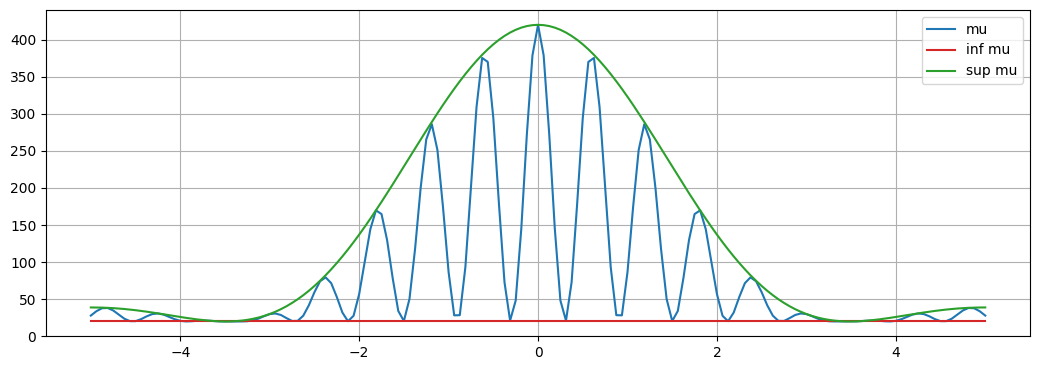

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

#inizializzo il generatore di numeri casuali locale
rng = np.random.default_rng(202609)

#scrivo la mia funzione di partenza scrivendo i 2 pezzi principali 
def E(x, alpha):
    return np.sinc(alpha*x/np.pi)**2 #inviluppo di difrazione
def C(x, delta):
    return np.cos(delta*x)**2 #termine di interferenza

#scrivo la funzione mu intera
def mu(x, B, I, alpha, delta):
    return B + I*E(x, alpha)*C(x, delta) 

#definisco i parametri iniziali
B = 20 #fondo uniforme
I = 400 #scala di segnale
alpha = 0.9 #larghezza dell'inviluppo (mm^-1)
delta = 5.2 #frequenza spaziale delle frange (mm^-1)

#creo l'array: 161 punti equidistanti nell'intervallo -5,5 mm
x_plot = np.linspace(-5, 5, 161)

#verifico che è positiva
mu(x_plot, B, I, alpha, delta)
mu_values = mu(x_plot, B, I, alpha, delta) #valori di mu

if np.all(mu_values >= 0):
    print("La funzione è sempre non negativa")

else: print("La funzione cambia segno")

#verifico che è simmetrica
mu_opposite = mu(-x_plot,B, I, alpha, delta) #valori di mu per valori di x di segno opposto

simmetrica = True

for i in range(len(x_plot)):
    if abs(mu_values[i] - mu(-x_plot[i], B, I, alpha, delta)) > 1e-10:
        simmetrica = False
        break

if simmetrica:
    print("La funzione è simmetrica rispetto all'asse y")
else:
    print("La funzione non è simmetrica rispetto all'asse y")


#verifico che è compatibile con B+Io (è una verifica che sii fa per il punto x=0)
idx_0 = len(x_plot) // 2 #trova l'inice dove x=0
mu_0 = mu_values[idx_0]
atteso_0 = B + I

differenza_0 = mu_0 - atteso_0 #differenza rispetto al valore atteso

if np.isclose(mu_0, atteso_0, rtol=1e-10, atol=1e-10):
    print("Conclusione: mu(0) è perfettamente compatibile con B + I0 ")
else:
    print("Conclusione: mu(0) si discosta dal valore atteso.")

#inviluppo superiore B+I*E
def mu_sup( x, B, I, alpha):
    return B + I*E(x, alpha)


mu_sup_values = mu_sup(x_plot, B, I, alpha)
B_plot = np.full(161, B)

#rappresentazione grafica
fig, axes = plt.subplots (figsize=(10.5, 3.8))
axes.plot(x_plot, mu_values, color="tab:blue", label="mu")
axes.plot(x_plot, B_plot, color="tab:red", label="inf mu")
axes.plot(x_plot, mu_sup_values, color="tab:green", label="sup mu")
axes.grid(True)

plt.tight_layout()
plt.legend()
plt.show()


Il parametro che controlla la larghezza del massimo centrale è l'alpha, mentreil delta è il parametro che controlla la distanza tra le frange.
Inoltre x=0 non è considerabile come singolarità fisica perchè il limite del rapporto E(x) per x->0 vale 1, infatti la funzione è continua in 0.

0.380181308029248
Conteggi totali nella regione centrale (Nc): 10657
Valore atteso nella regione centrale (mu_c): 10617.83
Differenza (Nc - mu_c): 39.17
Incertezza statistica attesa (sqrt(mu_c)): 103.04
Z-score (|Nc - mu_c| / sqrt(mu_c)): 0.38


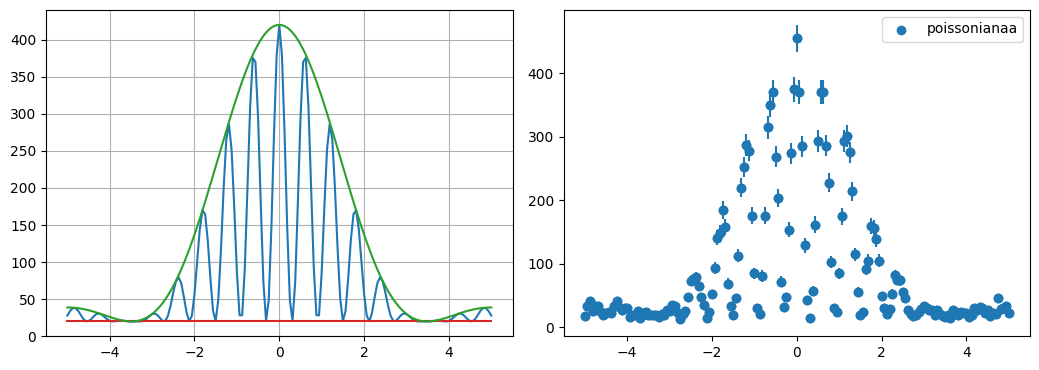

In [ ]:
#pt.2
def sum_n_i (values, x):
    mask = x < 1.2
    return np.sum(values[mask])

def compare_with_error(valore, incertezza):
    z_score = abs(valore) / incertezza #valore assoluto 
    return z_score

# Generazione di una singola acquisizione indipendente con statistica di Poisson
n_i = rng.poisson(mu_values)
n_i_err = np.sqrt(n_i)
n_i_err[n_i == 0] = 1.0 #errore uguale a 1 dove il conteggio è 0

res = sum_n_i(n_i, x_plot) - sum_n_i(mu(x_plot, B, I, alpha, delta), x_plot)
sigma_res = np.sqrt(sum_n_i(mu(x_plot, B, I, alpha, delta), x_plot))

#grafico
fig, axes = plt.subplots (1, 2, figsize=(10.5, 3.8))

axes[0].plot(x_plot, mu_values, color="tab:blue", label="mu")
axes[0].plot(x_plot, B_plot, color="tab:red", label="inf mu")
axes[0].plot(x_plot, mu_sup_values, color="tab:green", label="sup mu")
axes[0].grid(True)

axes[1].scatter(x_plot, n_i, color="tab:blue", label="poissonianaa")
axes[1].errorbar(x_plot, n_i, n_i_err, fmt='o', color="tab:blue")

print(compare_with_error(res, sigma_res))
plt.tight_layout()
plt.legend()
plt.show

# Calcolo dei conteggi nella regione centrale e del valore atteso corrispondente
Nc = sum_n_i(n_i, x_plot)
mu_c = sum_n_i(mu(x_plot, B, I, alpha, delta), x_plot)

differenza = Nc - mu_c
sigma_c = np.sqrt(mu_c)
z_score = abs(differenza) / sigma_c

print(f"Conteggi totali nella regione centrale (Nc): {Nc}")
print(f"Valore atteso nella regione centrale (mu_c): {mu_c:.2f}")
print(f"Differenza (Nc - mu_c): {differenza:.2f}")
print(f"Incertezza statistica attesa (sqrt(mu_c)): {sigma_c:.2f}")
print(f"Z-score (|Nc - mu_c| / sqrt(mu_c)): {z_score:.2f}")


Poiché lo scostamento ottenuto è ampiamente inferiore a 1 deviazione standard la differenza ottenuta è compatibile con una normale fluttuazione statistica casuale nel processo di conteggio poissoniano.

Media simulata: 7653.60
Deviazione standard (dof=1): 88.16
Previsione teorica della deviazione standard (sqrt(mu_c)): 103.04
Errore sulla media delle simulazioni: 1.971
Scarto relativo: 0.27917


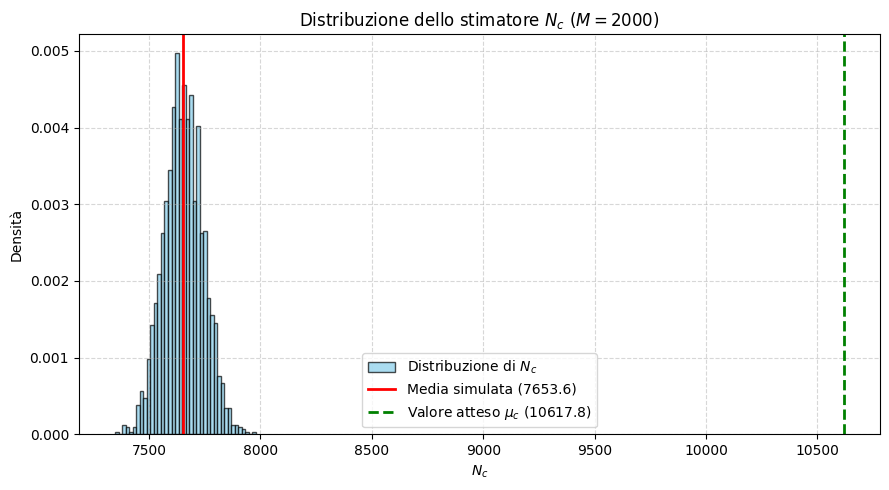

In [ ]:
# attività 3
M = 2000
# Ogni riga della matrice simulata rappresenta un esperimento completo
matrice_conteggi = rng.poisson(lam=mu_values, size=(M, len(x_plot)))

#calcoliamo N_c nella regione centrale
mask_centrale = np.abs(x_plot) < 1.2 #per la regione centrale
N_c_j = np.sum(matrice_conteggi[:, mask_centrale], axis=1) #sommiamo lungo l'asse 1 

#statistiche sulla distribuzione di nc
media_simulata = np.mean(N_c_j)
std_simulata = np.std(N_c_j, ddof=1) # Deviazione standard con dof=1
errore_media = std_simulata / np.sqrt(M)
scarto_relativo = abs(media_simulata - mu_c) / mu_c
previsione_teorica = np.sqrt(mu_c)

print(f"Media simulata: {media_simulata:.2f}")
print(f"Deviazione standard (dof=1): {std_simulata:.2f}")
print(f"Previsione teorica della deviazione standard (sqrt(mu_c)): {previsione_teorica:.2f}")
print(f"Errore sulla media delle simulazioni: {errore_media:.3f}")
print(f"Scarto relativo: {scarto_relativo:.5f}")

#ora facciamo l'istogramma
plt.figure(figsize=(9, 5))
plt.hist(N_c_j, bins=40, density=True, alpha=0.7, color='skyblue', edgecolor='black', label='Distribuzione di $N_c$')
plt.axvline(media_simulata, color='red', linestyle='-', linewidth=2, label=f'Media simulata ({media_simulata:.1f})')
plt.axvline(mu_c, color='green', linestyle='--', linewidth=2, label=f'Valore atteso $\mu_c$ ({mu_c:.1f})')

plt.xlabel(r'$N_c$')
plt.ylabel('Densità')
plt.title(f'Distribuzione dello stimatore $N_c$ ($M = {M}$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()





La quantità che descrive l’incertezza di una singola acquisizione è la deviazione strandard della singola misura.
Se aumento M vado a ridurre l'errore sulla media delle simulazioni, ottenedo una forma migliore della distribuzione.
Infine la sottrazione di un fondo noto non elimina le fluttuazioni generate dagli eventi di fondo ma corregge il valore atteso.